In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import math

from scipy.stats import pearsonr
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


In [98]:
df = pd.read_csv("data_reg.csv")
print(df.head())

# If Date is in dd-mm-YYYY format, parse it like this:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Make sure rows are in time order before using lag/shift
df = df.sort_values("Date").reset_index(drop=True)

         Date   Bund    BTP  DFR  ON-GcPooling  ON-ExtGcPooling  TN-GcPooling  \
0  24-02-2026  2.707  3.314  2.0         2.004            2.011         2.011   
1  23-02-2026  2.711  3.319  2.0         2.000            2.014         2.008   
2  20-02-2026  2.737  3.340  2.0         2.011            2.021         2.013   
3  19-02-2026  2.743  3.350  2.0         2.014            2.021         2.015   
4  18-02-2026  2.739  3.345  2.0         2.006            2.012         2.016   

   TN-ExtGcPooling  SN-GcPooling  SN-ExtGcPooling  ...  ON-GcPoolingVol  \
0            2.015         2.015            2.015  ...            21056   
1            2.016         2.011            2.019  ...            11000   
2            2.020         2.011            2.020  ...            14101   
3            2.020         2.015            2.020  ...            13490   
4            2.019         2.012            2.020  ...            17991   

   ON-ExtGcPoolingVol  TN-GcPoolingVol  TN-ExtGcPoolingVol  SN

In [99]:
df["ECB_deferred_rate_new"] = (
    df["ON-GcPooling"] * df["ON-GcPoolingVol"]
    + df["TN-GcPooling"].shift(1) * df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPooling"].shift(2) * df["SN-GcPoolingVol"].shift(2)
) / (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["ECB_deferred_vol_new"] = (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["EXT_deferred_rate_new"] = (
    df["ON-ExtGcPooling"] * df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPooling"].shift(1) * df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPooling"].shift(2) * df["SN-ExtGcPoolingVol"].shift(2)
) / (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

df["EXT_deferred_vol_new"] = (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

# Spread
df["DeferredRateSpread"] = df["EXT_deferred_rate_new"] - df["ECB_deferred_rate_new"]

# BTP-Bund spread (this part you intended as subtraction)
df["BTP_Bund_Spread"] = df["BTP"] - df["Bund"]

df["ExcessLiquidityLn"] = np.log(df["ExcessLiquidity"])

#Volume Spread
df["Volume_Spread"] = df["ECB_deferred_vol_new"] - df["EXT_deferred_vol_new"]
df["Liquidity_ratio"] = np.log(df["ECB_deferred_vol_new"]/ df["EXT_deferred_vol_new"])

df.head()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Date,Bund,BTP,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,SN-GcPooling,SN-ExtGcPooling,...,MLF,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
0,2010-01-05,3.373,4.101,0.25,0.293,0.319,0.326,0.330,0.335,0.330,...,1.75,NaN,NaN,NaN,NaN,NaN,0.728,12.189160,NaN,NaN
1,2010-01-06,3.381,4.120,0.25,0.274,0.313,0.295,0.316,0.335,0.319,...,1.75,NaN,NaN,NaN,NaN,NaN,0.739,12.042477,NaN,NaN
2,2010-01-07,3.370,4.094,0.25,0.283,0.308,0.290,0.304,0.305,0.318,...,1.75,0.296702,10845.0,0.317555,2407.0,0.020853,0.724,12.061267,8438.0,1.505323
3,2010-01-08,3.385,4.078,0.25,0.282,0.319,0.324,0.321,0.327,0.323,...,1.75,0.285156,14131.0,0.314854,3075.0,0.029697,0.693,12.061267,11056.0,1.525066
4,2010-01-11,3.347,4.057,0.25,0.264,0.280,0.294,0.293,0.318,0.320,...,1.75,0.283652,13776.0,0.318093,2423.0,0.034442,0.710,12.111537,11353.0,1.737922


In [100]:
#Conver to basis points
rate_cols = [
    "Bund", "BTP",
    "ON-GcPooling", "ON-ExtGcPooling",
    "TN-GcPooling", "TN-ExtGcPooling",
    "SN-GcPooling", "SN-ExtGcPooling",
    "DeferredRate",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new",
    "DeferredRateSpread", "BTP_Bund_Spread","DFR", "MRO","MLF"
]

df[rate_cols] = df[rate_cols] * 100

In [101]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.sort_values("Date").copy()
df=df.dropna()
df.columns
df.head()

,Date,Bund,BTP,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,SN-GcPooling,SN-ExtGcPooling,...,MLF,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
2,2010-01-07,337.0,409.4,25.0,28.3,30.8,29.0,30.4,30.5,31.8,...,175.0,29.670217,10845.0,31.755546,2407.0,2.085330,72.4,12.061267,8438.0,1.505323
3,2010-01-08,338.5,407.8,25.0,28.2,31.9,32.4,32.1,32.7,32.3,...,175.0,28.515618,14131.0,31.485366,3075.0,2.969748,69.3,12.061267,11056.0,1.525066
4,2010-01-11,334.7,405.7,25.0,26.4,28.0,29.4,29.3,31.8,32.0,...,175.0,28.365157,13776.0,31.809327,2423.0,3.444170,71.0,12.111537,11353.0,1.737922
5,2010-01-12,331.3,405.5,25.0,25.2,27.9,26.2,28.1,27.7,29.2,...,175.0,27.985336,16885.0,29.925233,3646.0,1.939897,74.2,12.138917,13239.0,1.532795
6,2010-01-13,330.3,408.9,25.0,25.3,26.1,26.2,27.0,26.5,27.5,...,175.0,27.346796,12875.0,28.502926,3760.0,1.156129,78.6,12.180539,9115.0,1.230868


In [141]:
df2 = df[[
    "Date",
    "ExcessLiquidity",
    "ExcessLiquidityLn",
    "BTP_Bund_Spread",
    "DeferredRateSpread",
    "ECB_deferred_vol_new",
    "EXT_deferred_vol_new",
    "Liquidity_ratio","Bund", "BTP",
        "DFR","MRO","MLF",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new", "DeferredVol", "DeferredRate"
    #"Stress_State"
]].dropna().copy()


# 1. Define the outlier boundaries (1st and 99th percentiles)
lower_cutoff = df2['DeferredRateSpread'].quantile(0.05)
upper_cutoff = df2['DeferredRateSpread'].quantile(0.95)

# 2. Create the cleaned dataframe
# We use .copy() to ensure we aren't working on a slice of the original df
df3 = df2[(df2['DeferredRateSpread'] > lower_cutoff) & 
               (df2['DeferredRateSpread'] < upper_cutoff)].copy()

df3["Deferred_MA"] = df3["DeferredRateSpread"].rolling(window=5).mean()
df3['d_log_Excess'] = df3['ExcessLiquidityLn'].diff()
df3 = df3[df3['Date'] >= "2016-01-01"].copy()


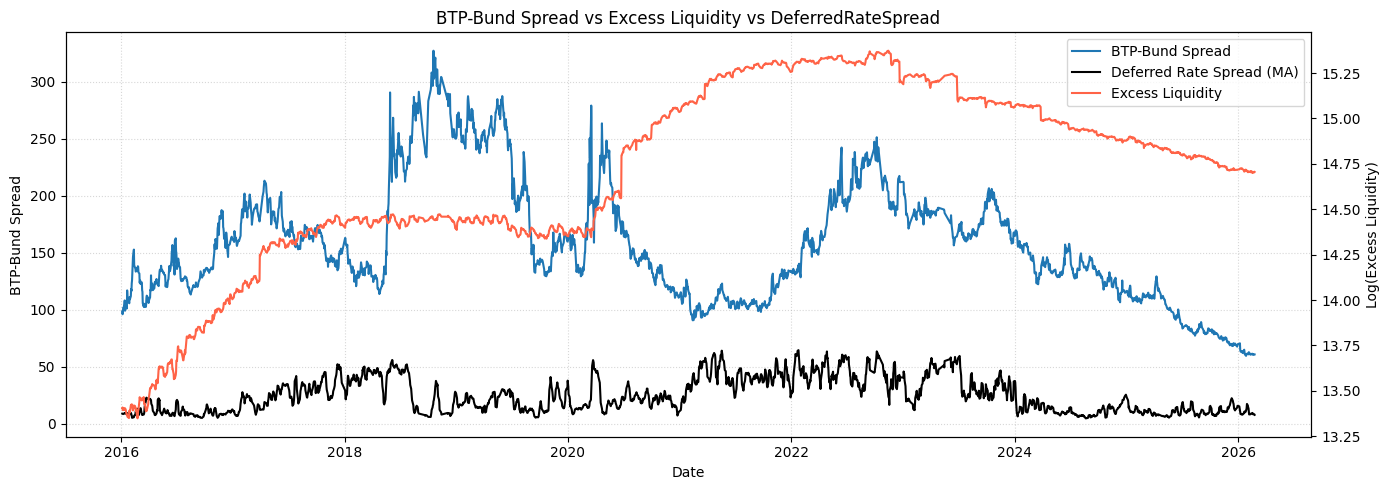

In [135]:
df3['dummy']= df3["Deferred_MA"]*10
df3['Delta_Liquidity']= df3["ExcessLiquidityLn"].diff(60)

fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(df3["Date"], df3["BTP_Bund_Spread"], label="BTP-Bund Spread")
ax1.set_xlabel("Date")
ax1.set_ylabel("BTP-Bund Spread")
ax1.plot(df3["Date"], df3["dummy"],
         label="Deferred Rate Spread (MA)", color="black")
ax2 = ax1.twinx()
ax2.plot(df3["Date"], df3["ExcessLiquidityLn"], label="Excess Liquidity", color = "tomato")
ax2.set_ylabel("Log(Excess Liquidity)")

ax1.set_title("BTP-Bund Spread vs Excess Liquidity vs DeferredRateSpread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

In [136]:
df3.head()

,Date,ExcessLiquidity,ExcessLiquidityLn,BTP_Bund_Spread,DeferredRateSpread,ECB_deferred_vol_new,EXT_deferred_vol_new,Liquidity_ratio,Bund,BTP,...,MRO,MLF,ECB_deferred_rate_new,EXT_deferred_rate_new,DeferredVol,DeferredRate,Deferred_MA,d_log_Excess,dummy,Delta_Liquidity
1535,2016-01-04,662720,13.404108,98.3,0.867555,11927.0,9496.0,0.227934,56.6,154.9,...,5.0,30.0,-29.559973,-28.692418,21423.0,-29.2,0.872573,0.002865,8.725735,NaN
1536,2016-01-05,665327,13.408034,95.9,0.751526,15233.0,10443.0,0.377532,54.0,149.9,...,5.0,30.0,-29.405994,-28.654467,25676.0,-29.1,0.855003,0.003926,8.550033,NaN
1537,2016-01-06,655745,13.393527,97.9,0.930508,13102.0,12889.0,0.016391,50.3,148.2,...,5.0,30.0,-29.295680,-28.365172,25991.0,-28.8,0.847925,-0.014507,8.479250,NaN
1538,2016-01-07,660965,13.401456,101.4,0.908202,15769.0,10539.0,0.402963,53.9,155.3,...,5.0,30.0,-29.268597,-28.360395,26308.0,-28.9,0.839375,0.007929,8.393751,NaN
1539,2016-01-08,660965,13.401456,101.4,0.836180,16604.0,10372.0,0.470534,51.4,152.8,...,5.0,30.0,-29.336624,-28.500444,26976.0,-29.0,0.858794,0.000000,8.587944,NaN


In [144]:
# 1. Feature Engineering on df
df3['Lagged_Spread'] = df3['DeferredRateSpread'].shift(1)
df3['Lagged_rate'] = df3['DeferredRate'].shift(1)
df3['Delta_Liquidity'] = df3['ExcessLiquidityLn'].diff(30)
df3['Lag_DFR']= df3['DFR'].shift(30)
df3['ratio']=df3['BTP_Bund_Spread']/df3['ExcessLiquidityLn']
df3['mul']=df3['BTP_Bund_Spread']*df3['ExcessLiquidityLn']
df3.dropna()


,Date,ExcessLiquidity,ExcessLiquidityLn,BTP_Bund_Spread,DeferredRateSpread,ECB_deferred_vol_new,EXT_deferred_vol_new,Liquidity_ratio,Bund,BTP,...,DeferredVol,DeferredRate,Deferred_MA,d_log_Excess,Lagged_Spread,Lagged_rate,Delta_Liquidity,Lag_DFR,ratio,mul
1567,2016-02-17,662195,13.403315,133.3,1.726999,9418.0,10602.0,-0.118420,26.9,160.2,...,20020.0,-28.3,1.060201,0.001431,1.020055,-28.3,-0.000793,-30.0,9.945301,1786.661937
1568,2016-02-18,653153,13.389567,133.6,1.371896,9253.0,8143.0,0.127789,21.8,155.4,...,17396.0,-28.6,1.184155,-0.013749,1.726999,-28.3,-0.018467,-30.0,9.977918,1788.846109
1569,2016-02-19,653153,13.389567,136.2,1.171290,10978.0,8880.0,0.212092,20.2,156.4,...,19858.0,-28.4,1.200464,0.000000,1.371896,-28.6,-0.003961,-30.0,10.172099,1823.658982
1570,2016-02-22,630709,13.354600,134.3,1.258246,11680.0,9846.0,0.170813,17.6,151.9,...,21526.0,-28.4,1.309697,-0.034967,1.171290,-28.4,-0.046856,-30.0,10.056460,1793.522762
1571,2016-02-23,626667,13.348171,134.8,0.732830,9261.0,10658.0,-0.140499,18.3,153.1,...,19919.0,-28.5,1.252252,-0.006429,1.258246,-28.4,-0.053286,-30.0,10.098762,1799.333394
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4127,2026-02-18,2436418,14.706039,60.6,0.600197,25801.0,9962.0,0.951635,273.9,334.5,...,35763.0,200.9,0.886672,0.005101,1.018388,200.9,-0.014321,200.0,4.120756,891.185993
4128,2026-02-19,2426474,14.701950,60.7,0.675299,20190.0,10635.0,0.641037,274.3,335.0,...,30825.0,201.6,0.815617,-0.004090,0.600197,200.9,-0.021433,200.0,4.128704,892.408349
4129,2026-02-20,2428285,14.702696,60.3,0.883202,20847.0,7256.0,1.055381,273.7,334.0,...,28103.0,201.4,0.825689,0.000746,0.675299,201.6,-0.022282,200.0,4.101289,886.572557
4130,2026-02-23,2429499,14.703196,60.8,0.917568,20950.0,8067.0,0.954357,271.1,331.9,...,29017.0,200.9,0.818931,0.000500,0.883202,201.4,-0.021811,200.0,4.135155,893.954294


# CISS

In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Prepare Data (Handle NaNs)
df_clust = df3[['CISS_MM', 'Deferred_MA']].dropna().copy()

# 2. Standardize (Crucial for K-Means)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clust)

# 3. K-Means for CISS
km_ciss = KMeans(n_clusters=2, random_state=42, n_init=10)
df_clust['Cluster_CISS'] = km_ciss.fit_predict(df_clust[['CISS_MM']])

# 4. K-Means for Repo Spread (Deferred_MA)
km_repo = KMeans(n_clusters=2, random_state=42, n_init=10)
df_clust['Cluster_Repo'] = km_repo.fit_predict(df_clust[['Deferred_MA']])

# 5. Alignment Fix
# K-means labels (0 and 1) are arbitrary. Let's ensure '1' always means 'High Stress'
if df_clust.groupby('Cluster_CISS')['CISS_MM'].mean().idxmin() == 1:
    df_clust['Cluster_CISS'] = 1 - df_clust['Cluster_CISS']
    
if df_clust.groupby('Cluster_Repo')['Deferred_MA'].mean().idxmin() == 1:
    df_clust['Cluster_Repo'] = 1 - df_clust['Cluster_Repo']

KeyError: "['CISS_MM'] not in index"

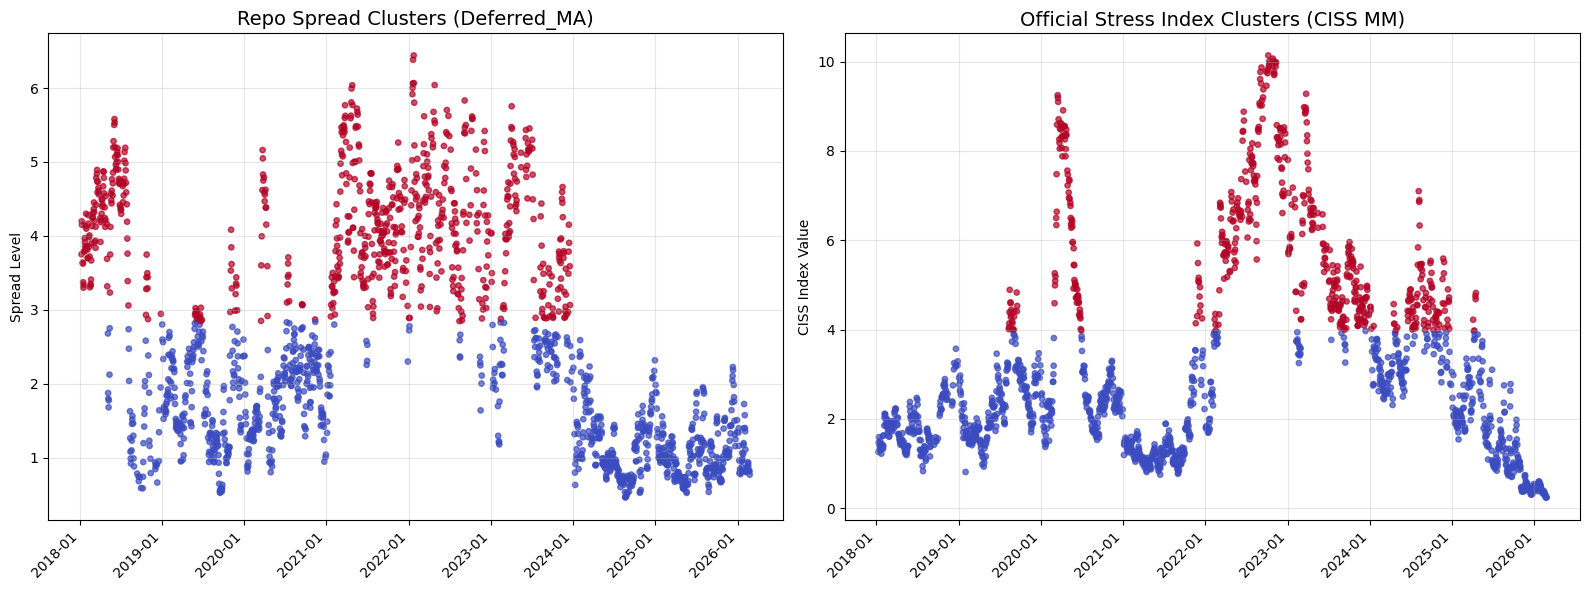

In [11]:
# Assuming df_bQE has a 'Date' column
df_clust['Date'] = df3.loc[df_clust.index, 'Date']
df_clust['Date'] = pd.to_datetime(df_clust['Date'])
import matplotlib.dates as mdates

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Repo Spread Clusters
ax1.scatter(df_clust['Date'], df_clust['Deferred_MA'], 
            c=df_clust['Cluster_Repo'], cmap='coolwarm', s=15, alpha=0.7)
ax1.set_title('Repo Spread Clusters (Deferred_MA)', fontsize=14)
ax1.set_ylabel('Spread Level')

# Subplot 2: CISS MM Clusters
ax2.scatter(df_clust['Date'], df_clust['CISS_MM'], 
            c=df_clust['Cluster_CISS'], cmap='coolwarm', s=15, alpha=0.7)
ax2.set_title('Official Stress Index Clusters (CISS MM)', fontsize=14)
ax2.set_ylabel('CISS Index Value')

# Apply Date Formatting to both axes
for ax in [ax1, ax2]:
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Markov Switching Model

In [145]:
df3['ratiod']= df3['BTP_Bund_Spread']/df3['Delta_Liquidity']


In [146]:
df_QE = df3[(df3['Date'] >='2020-06-01')  & (df3['Date'] <'2022-01-01')]
df_bQE = df3[df3['Date'] <'2020-06-01']
df_QT = df3[df3['Date'] >='2022-01-01']

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


                        Markov Switching Model Results                        
Dep. Variable:            Deferred_MA   No. Observations:                 2376
Model:               MarkovRegression   Log Likelihood               -1405.594
Date:                Wed, 15 Apr 2026   AIC                           2839.189
Time:                        22:05:02   BIC                           2920.013
Sample:                             0   HQIC                          2868.608
                               - 2376                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9095      0.029     99.939      0.000       2.852       2.967
x1             0.8678      0.024     35.718      0.0

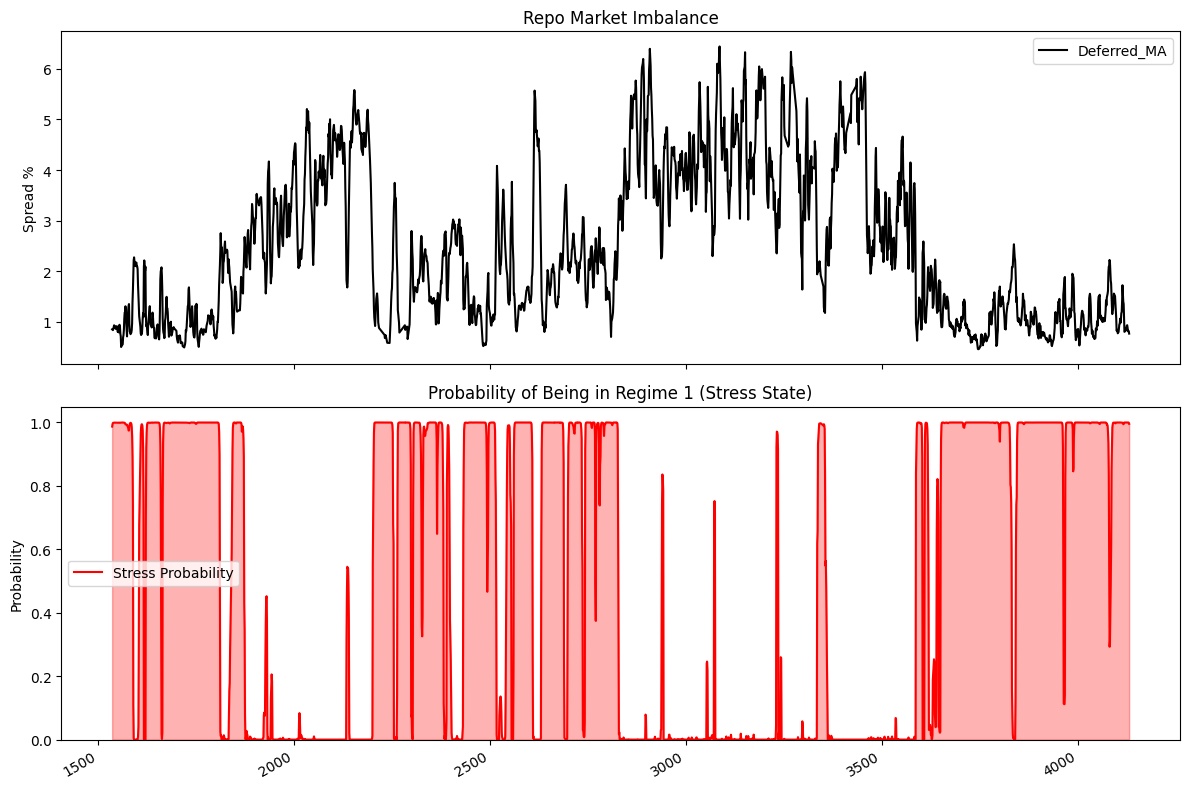

In [155]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1) Build one clean model dataframe
cols = [
    'Deferred_MA',
    'Lagged_Spread',
    'BTP_Bund_Spread',
    'ExcessLiquidityLn','MLF', 'DFR'
]

# If you have a Date column, uncomment these lines:
# df_bQE = df_bQE.copy()
# df_bQE['Date'] = pd.to_datetime(df_bQE['Date'], errors='coerce')
# df_bQE = df_bQE.dropna(subset=['Date']).sort_values('Date').set_index('Date')

data_msm = df3[cols].copy()
data_msm = data_msm.dropna().sort_index()

# 2) Define y and X from the same aligned frame
y = data_msm['Deferred_MA']
X = data_msm[['Lagged_Spread', 'BTP_Bund_Spread', 'ExcessLiquidityLn','DFR']]

# 3) Scale X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4) Fit Markov switching model
model_msm = sm.tsa.MarkovRegression(
    endog=y,
    k_regimes=2,
    exog=X_scaled,
    switching_variance=True
)

res_msm = model_msm.fit(search_reps=20, em_iter=10, disp=False)
print(res_msm.summary())

# 5) Plot
prob_stress = np.asarray(res_msm.smoothed_marginal_probabilities)[:, 1]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(data_msm.index, y, label='Deferred_MA', color='black')
axes[0].set_title('Repo Market Imbalance')
axes[0].set_ylabel('Spread %')
axes[0].legend()

axes[1].plot(data_msm.index, prob_stress, color='red', label='Stress Probability')
axes[1].fill_between(data_msm.index, 0, prob_stress, color='red', alpha=0.3)
axes[1].set_title('Probability of Being in Regime 1 (Stress State)')
axes[1].set_ylabel('Probability')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                        Markov Switching Model Results                        
Dep. Variable:            Deferred_MA   No. Observations:                  393
Model:               MarkovRegression   Log Likelihood                -216.505
Date:                Wed, 15 Apr 2026   AIC                            457.010
Time:                        18:10:29   BIC                            504.696
Sample:                             0   HQIC                           475.907
                                - 393                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5633        nan        nan        nan         nan         nan
x1            -0.3757   5.54e-16  -6.78e+14      0.0

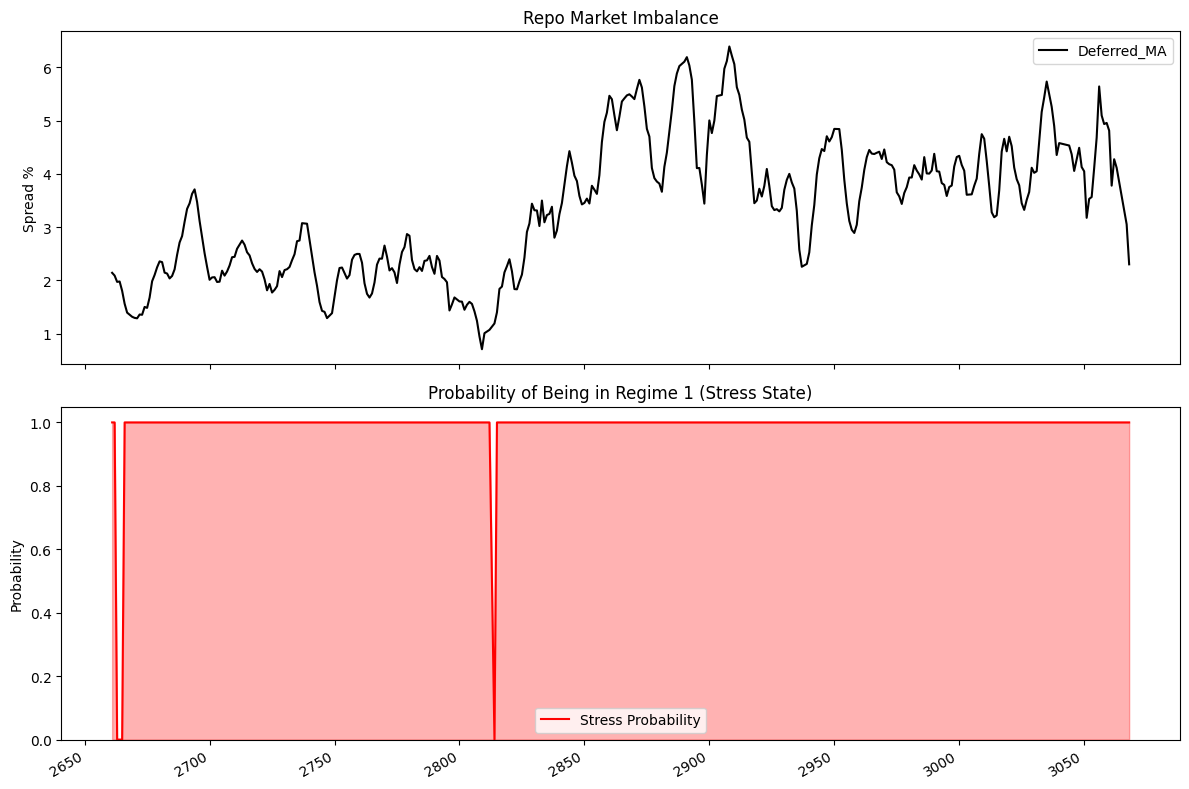

In [130]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1) Build one clean model dataframe
cols = [
    'Deferred_MA',
    'Lagged_Spread',
    'BTP_Bund_Spread',
    'ExcessLiquidityLn',
    'ratio',
]

# If you have a Date column, uncomment these lines:
# df_bQE = df_bQE.copy()
# df_bQE['Date'] = pd.to_datetime(df_bQE['Date'], errors='coerce')
# df_bQE = df_bQE.dropna(subset=['Date']).sort_values('Date').set_index('Date')

data_msm = df_QE[cols].copy()
data_msm = data_msm.dropna().sort_index()

# 2) Define y and X from the same aligned frame
y = data_msm['Deferred_MA']
X = data_msm[['Lagged_Spread', 'BTP_Bund_Spread', 'ExcessLiquidityLn']]

# 3) Scale X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4) Fit Markov switching model
model_msm = sm.tsa.MarkovRegression(
    endog=y,
    k_regimes=2,
    exog=X_scaled,
    switching_variance=True
)

res_msm = model_msm.fit(search_reps=20, em_iter=10, disp=False)
print(res_msm.summary())

# 5) Plot
prob_stress = np.asarray(res_msm.smoothed_marginal_probabilities)[:, 1]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(data_msm.index, y, label='Deferred_MA', color='black')
axes[0].set_title('Repo Market Imbalance')
axes[0].set_ylabel('Spread %')
axes[0].legend()

axes[1].plot(data_msm.index, prob_stress, color='red', label='Stress Probability')
axes[1].fill_between(data_msm.index, 0, prob_stress, color='red', alpha=0.3)
axes[1].set_title('Probability of Being in Regime 1 (Stress State)')
axes[1].set_ylabel('Probability')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


                        Markov Switching Model Results                        
Dep. Variable:            Deferred_MA   No. Observations:                  946
Model:               MarkovRegression   Log Likelihood                -514.666
Date:                Wed, 15 Apr 2026   AIC                           1053.333
Time:                        16:21:15   BIC                           1111.560
Sample:                             0   HQIC                          1075.523
                                - 946                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.7310      0.049     55.816      0.000       2.635       2.827
x1             0.7615      0.041     18.710      0.0

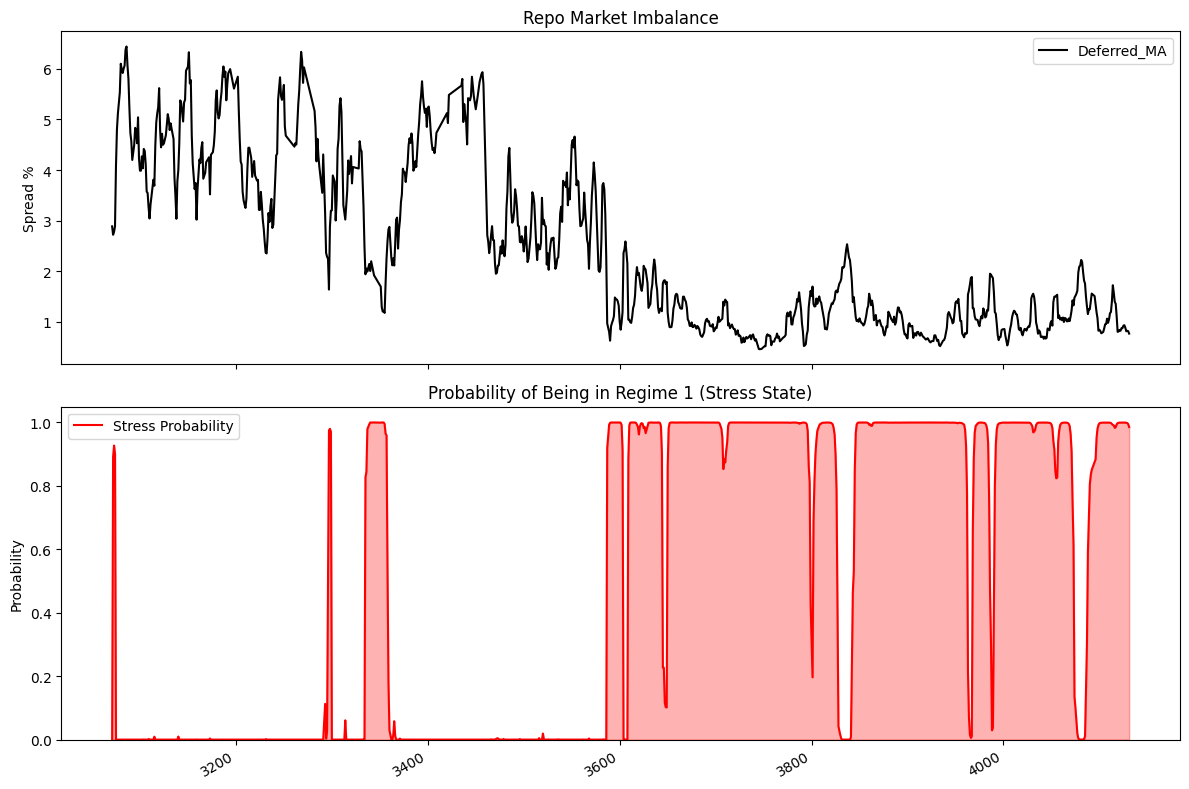

In [93]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1) Build one clean model dataframe
cols = [
    'Deferred_MA',
    'Lagged_Spread',
    'BTP_Bund_Spread',
    'ExcessLiquidityLn',
    'ratio'
]

# If you have a Date column, uncomment these lines:
# df_bQE = df_bQE.copy()
# df_bQE['Date'] = pd.to_datetime(df_bQE['Date'], errors='coerce')
# df_bQE = df_bQE.dropna(subset=['Date']).sort_values('Date').set_index('Date')

data_msm = df_QT[cols].copy()
data_msm = data_msm.dropna().sort_index()

# 2) Define y and X from the same aligned frame
y = data_msm['Deferred_MA']
X = data_msm[['Lagged_Spread', 'BTP_Bund_Spread','ExcessLiquidityLn']]

# 3) Scale X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4) Fit Markov switching model
model_msm = sm.tsa.MarkovRegression(
    endog=y,
    k_regimes=2,
    exog=X_scaled,
    switching_variance=True
)

res_msm = model_msm.fit(search_reps=20, em_iter=10, disp=False)
print(res_msm.summary())

# 5) Plot
prob_stress = np.asarray(res_msm.smoothed_marginal_probabilities)[:, 1]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(data_msm.index, y, label='Deferred_MA', color='black')
axes[0].set_title('Repo Market Imbalance')
axes[0].set_ylabel('Spread %')
axes[0].legend()

axes[1].plot(data_msm.index, prob_stress, color='red', label='Stress Probability')
axes[1].fill_between(data_msm.index, 0, prob_stress, color='red', alpha=0.3)
axes[1].set_title('Probability of Being in Regime 1 (Stress State)')
axes[1].set_ylabel('Probability')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Regime Shift OLS

In [54]:
df_QT  = df3[df3['Date'] >= "2022-07-01"].copy()

df_QE  = df3[(df3['Date'] >= "2021-02-01").copy()]


In [132]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

#df_bQE= df3[(df3['Date'] < "2020-03-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'BTP_Bund_Spread + '
    #'Delta_Liquidity '    # The Daily Flow Shock
    'ExcessLiquidityLn '  # The Stock Level
    #'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df3).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     2107.
Date:                Wed, 15 Apr 2026   Prob (F-statistic):               0.00
Time:                        18:12:01   Log-Likelihood:                -2190.0
No. Observations:                2376   AIC:                             4388.
Df Residuals:                    2372   BIC:                             4411.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -4.5172      0.54

In [56]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

#df_bQE= df3[(df3['Date'] < "2020-03-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'Log_BTP_Bund_Spread + '
    #'Delta_Liquidity '    # The Daily Flow Shock
    'ExcessLiquidityLn +'  # The Stock Level
    'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df_QT).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.846
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                     376.1
Date:                Sun, 12 Apr 2026   Prob (F-statistic):          1.58e-182
Time:                        21:45:10   Log-Likelihood:                -641.74
No. Observations:                 810   AIC:                             1293.
Df Residuals:                     805   BIC:                             1317.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             -45.2416    

# Dickey Fuller Test

In [122]:
from statsmodels.tsa.stattools import adfuller

def run_adf_test(series, name):
    print(f"--- ADF Test Results for: {name} ---")
    # autolag='AIC' chooses the best number of lags for the test automatically
    result = adfuller(series, autolag='AIC')
    
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print(f'Lags Used: {result[2]}')
    print(f'Observations: {result[3]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')
    
    if result[1] <= 0.05:
        print("\nResult: THE SERIES IS STATIONARY (Reject H0)")
    else:
        print("\nResult: THE SERIES IS NON-STATIONARY (Fail to reject H0)")
    print("-" * 40)

# Run it on your dependent variable
run_adf_test(df_QE['Deferred_MA'], "Repo Spread (QE)")

--- ADF Test Results for: Repo Spread (QE) ---
ADF Statistic: -3.2649
p-value: 0.0165
Lags Used: 21
Observations: 1409
Critical Values:
	1%: -3.435
	5%: -2.864
	10%: -2.568

Result: THE SERIES IS STATIONARY (Reject H0)
----------------------------------------


In [130]:
from statsmodels.tsa.stattools import adfuller

def run_adf_test(series, name):
    print(f"--- ADF Test Results for: {name} ---")
    # autolag='AIC' chooses the best number of lags for the test automatically
    result = adfuller(series, autolag='AIC')
    
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print(f'Lags Used: {result[2]}')
    print(f'Observations: {result[3]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')
    
    if result[1] <= 0.05:
        print("\nResult: THE SERIES IS STATIONARY (Reject H0)")
    else:
        print("\nResult: THE SERIES IS NON-STATIONARY (Fail to reject H0)")
    print("-" * 40)

# Run it on your dependent variable
run_adf_test(df_QT['Deferred_MA'], "Repo Spread (QT)")

--- ADF Test Results for: Repo Spread (QT) ---
ADF Statistic: -2.2211
p-value: 0.1987
Lags Used: 22
Observations: 923
Critical Values:
	1%: -3.437
	5%: -2.865
	10%: -2.568

Result: THE SERIES IS NON-STATIONARY (Fail to reject H0)
----------------------------------------


In [128]:
from statsmodels.tsa.stattools import adfuller

def run_adf_test(series, name):
    print(f"--- ADF Test Results for: {name} ---")
    # autolag='AIC' chooses the best number of lags for the test automatically
    result = adfuller(series, autolag='AIC')
    
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print(f'Lags Used: {result[2]}')
    print(f'Observations: {result[3]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')
    
    if result[1] <= 0.05:
        print("\nResult: THE SERIES IS STATIONARY (Reject H0)")
    else:
        print("\nResult: THE SERIES IS NON-STATIONARY (Fail to reject H0)")
    print("-" * 40)

# Run it on your dependent variable
run_adf_test(df_bQE['Deferred_MA'].dropna(), "Repo Spread (Before QE)")

--- ADF Test Results for: Repo Spread (Before QE) ---
ADF Statistic: -3.4678
p-value: 0.0089
Lags Used: 23
Observations: 1282
Critical Values:
	1%: -3.435
	5%: -2.864
	10%: -2.568

Result: THE SERIES IS STATIONARY (Reject H0)
----------------------------------------


In [134]:
from scipy import stats
import pandas as pd
import numpy as np

def analyze_spread_distribution(df, period_name):
    # Drop NaNs to avoid calculation errors
    data = df['DeferredRateSpread'].dropna()
    
    # Basic Stats
    mean = data.mean()
    std = data.std()
    
    # Normality Tests
    # Jarque-Bera (Tests if Skewness=0 and Kurtosis=3)
    jb_stat, jb_p = stats.jarque_bera(data)
    
    # Shapiro-Wilk (Better for smaller samples, but good for confirmation)
    shapiro_stat, shapiro_p = stats.shapiro(data)
    
    print(f"--- Distribution Analysis: {period_name} ---")
    print(f"Observations: {len(data)}")
    print(f"Mean Spread:  {mean:.4f} | Std Dev: {std:.4f}")
    print(f"Skewness:     {data.skew():.2f}")
    print(f"Kurtosis:     {data.kurtosis():.2f} (Excess)") 
    print(f"Jarque-Bera p-value: {jb_p:.4e}")
    
    if jb_p < 0.05:
        print("RESULT: Significant Non-Normality detected.")
    else:
        print("RESULT: Data appears Gaussian (Normal).")
    print("-" * 45)

# Execute for your three periods
analyze_spread_distribution(df_bQE, "Before QE (Pre-2016)")
analyze_spread_distribution(df_QE, "During QE (2016-2022)")
analyze_spread_distribution(df_QT, "During QT (2022-Present)")

--- Distribution Analysis: Before QE (Pre-2016) ---
Observations: 1310
Mean Spread:  2.3019 | Std Dev: 1.4521
Skewness:     1.12
Kurtosis:     0.78 (Excess)
Jarque-Bera p-value: 3.1303e-67
RESULT: Significant Non-Normality detected.
---------------------------------------------
--- Distribution Analysis: During QE (2016-2022) ---
Observations: 1431
Mean Spread:  2.5289 | Std Dev: 1.5217
Skewness:     0.62
Kurtosis:     -0.50 (Excess)
Jarque-Bera p-value: 5.6122e-24
RESULT: Significant Non-Normality detected.
---------------------------------------------
--- Distribution Analysis: During QT (2022-Present) ---
Observations: 946
Mean Spread:  2.3740 | Std Dev: 1.8197
Skewness:     0.95
Kurtosis:     -0.27 (Excess)
Jarque-Bera p-value: 2.4578e-32
RESULT: Significant Non-Normality detected.
---------------------------------------------


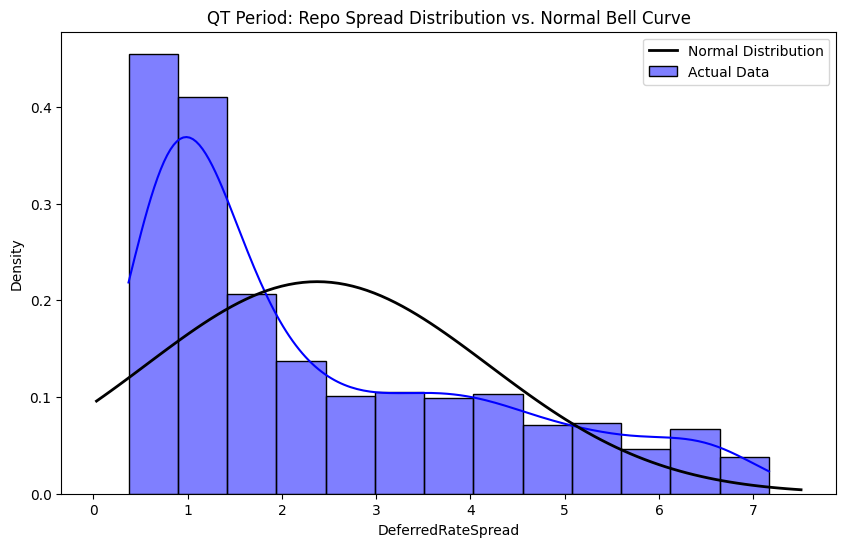

In [135]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df_QT['DeferredRateSpread'], kde=True, stat="density", color='blue', label='Actual Data')

# Overlay a theoretical normal distribution for comparison
mu, std = stats.norm.fit(df_QT['DeferredRateSpread'].dropna())
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2, label='Normal Distribution')

plt.title('QT Period: Repo Spread Distribution vs. Normal Bell Curve')
plt.legend()
plt.show()

In [144]:
def pre_flight_check_v3(df, name):
    print(f"\n{'='*20} PRE-FLIGHT CHECK: {name} {'='*20}")
    
    # Ensure we are looking at the right column and drop NaNs
    # Use .values to ensure we are looking at a clean array of numbers
    series = df['Deferred_MA'].dropna()
    
    obs_count = len(series)
    if obs_count < 30:
        print(f"❌ Error: Only {obs_count} observations found. The test needs more data!")
        print("Check if your date filters (e.g., < '2016-01-01') actually match your data.")
        return

    print(f"✅ Data Found: {obs_count} observations")

    # --- STEP 1: Unit Root (ADF) ---
    adf_result = adfuller(series, autolag='AIC')
    print(f"✅ Unit Root Check (ADF): p-value = {adf_result[1]:.4f}")

    # --- STEP 2: Distribution (JB) ---
    jb_stat, jb_p = stats.jarque_bera(series)
    print(f"✅ Distribution Check (JB): p-value = {jb_p:.4e}")
    print(f"   -> Skewness: {series.skew():.2f}")
    print(f"   -> Kurtosis: {series.kurtosis():.2f}")
    
    print("-" * 45)

# IMPORTANT: Check your data counts BEFORE running the function
print(f"Rows in df_bQE: {len(df_bQE)}")
print(f"Rows in df_QE: {len(df_QE)}")
print(f"Rows in df_QT: {len(df_QT)}")

# If those numbers are > 1, run this:
pre_flight_check_v3(df_bQE, "Before QE")
pre_flight_check_v3(df_QE, "During QE")
pre_flight_check_v3(df_QT, "During QT")

Rows in df_bQE: 1310
Rows in df_QE: 1431
Rows in df_QT: 946

==================== PRE-FLIGHT CHECK: Before QE ====================
✅ Data Found: 1306 observations
✅ Unit Root Check (ADF): p-value = 0.0089
✅ Distribution Check (JB): p-value = 1.7863e-38
   -> Skewness: 0.88
   -> Kurtosis: 0.32
---------------------------------------------

==================== PRE-FLIGHT CHECK: During QE ====================
✅ Data Found: 1431 observations
✅ Unit Root Check (ADF): p-value = 0.0165
✅ Distribution Check (JB): p-value = 5.2516e-22
   -> Skewness: 0.50
   -> Kurtosis: -0.80
---------------------------------------------

==================== PRE-FLIGHT CHECK: During QT ====================
✅ Data Found: 946 observations
✅ Unit Root Check (ADF): p-value = 0.1987
✅ Distribution Check (JB): p-value = 1.9541e-24
   -> Skewness: 0.74
   -> Kurtosis: -0.75
---------------------------------------------


In [143]:
import numpy as np
from scipy.stats import chi2

# 1. Fit a simple OLS for comparison
# Note: Ensure you use the same y and X as your Markov model
ols_model = sm.OLS(y, sm.add_constant(X)).fit()

# 2. Get the Log-Likelihoods
ll_ols = ols_model.llf
ll_msm = res_msm.llf # This is from your Markov model fit

# 3. Calculate the LR Statistic
# LR = 2 * (LL_Complex - LL_Simple)
lr_stat = 2 * (ll_msm - ll_ols)

# 4. Calculate p-value (Degrees of freedom = difference in number of parameters)
# Usually, for a 2-regime switching variance model, df is around 4-6
df_diff = 6 
p_val = 1 - chi2.cdf(lr_stat, df_diff)

print(f"--- Likelihood Ratio Test ---")
print(f"OLS Log-Likelihood: {ll_ols:.2f}")
print(f"MSM Log-Likelihood: {ll_msm:.2f}")
print(f"LR Statistic: {lr_stat:.2f}")
print(f"p-value: {p_val:.4e}")

if p_val < 0.05:
    print("RESULT: Markov Switching Model is STATISTICALLY SUPERIOR to OLS.")
else:
    print("RESULT: Stick to OLS (MSM does not add significant value).")

--- Likelihood Ratio Test ---
OLS Log-Likelihood: -849.99
MSM Log-Likelihood: -514.10
LR Statistic: 671.78
p-value: 0.0000e+00
RESULT: Markov Switching Model is STATISTICALLY SUPERIOR to OLS.
